# Ejercicio 6: Mediciones con ruido y mínimos cuadrados

En este ejercicio agregamos distintos niveles de ruido a las mediciones ideales producidas por $A_7$. Para cada nivel de ruido reconstruimos la imagen mediante mínimos cuadrados y analizamos la norma del residuo, el error relativo, los valores mínimos y máximos y la calidad visual de la reconstrucción.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Código utilizado de ejercicios anteriores

In [2]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

x_fantoma = X_fantoma.reshape(-1)

def mascara_rayo(n, direccion, s):

    matriz = np.array([[0] * n for _ in range(n)])      # creamos una matriz de n x n de ceros

    for i in range(0, n):      
        for j in range(0, n):
            if direccion[0] * i + direccion[1] * j == s:        # comprobamos si el píxel (i, j) pertenece al rayo
                matriz[i, j] = 1        # si pertenece al rayo, marcamos esa posición con un 1

    return matriz       # devolvemos la máscara del rayo


def matriz_proyeccion(n, direcciones):

    matriz = []     # acá vamos a guardar los vectores de todas las máscaras
    rayo = []       # acá vamos a guardar los pares de s y (alfa, beta) de cada rayo

    for direccion in direcciones:

        valores_s = []      # acá guardamos todos los valores posibles de s para la dirección actual

        # recorremos todos los píxeles
        for i in range(n):
            for j in range(n):
                valores_s.append(direccion[0] * i + direccion[1] * j)       # calculamos el valor de s que le corresponde al píxel (i, j) para esta dirección

        valores_s = sorted(set(valores_s))      # eliminamos los valores repetidos de s y los ordenamos de menor a mayor

        for s in valores_s:

            rayo.append((tuple(direccion), s))

            mascara = mascara_rayo(n, direccion, s)     # generamos la máscara de este rayo particular
            matriz.append(mascara.reshape(-1))      # convertimos la máscara de n x n en un vector y lo agregamos como una nueva fila

    return np.array(matriz) , rayo

# D2
D2 = [(1, 0), (0, 1)]
A2, rayos_A2 = matriz_proyeccion(8, D2)
rango_A2 = np.linalg.matrix_rank(A2)
nul_A2 = 64 - rango_A2


# D4
D4 = D2 + [(1, 1), (1, -1)]
A4, rayos_A4 = matriz_proyeccion(8, D4)
rango_A4 = np.linalg.matrix_rank(A4)
nul_A4 = 64 - rango_A4

# D7
D7 = D4 + [(2, 1), (1, 2), (3, 1)]
A7, rayos_A7 = matriz_proyeccion(8, D7)
rango_A7 = np.linalg.matrix_rank(A7)
nul_A7 = 64 - rango_A7


## a) Generación de las mediciones con ruido

Primero calculamos las mediciones ideales $b_7=A_7x_{\text{fantoma}}$. Luego generamos un único vector aleatorio $z$ con distribución normal estándar y lo utilizamos para construir todos los niveles de ruido.

Al mantener el mismo vector $z$, conservamos el mismo patrón de ruido y modificamos únicamente su intensidad mediante el valor de $\sigma$.

In [3]:
# Calculamos las mediciones ideales
b7 = A7 @ x_fantoma

# Fijamos una semilla para obtener siempre el mismo vector aleatorio
np.random.seed(18)

# Generamos un vector aleatorio del mismo tamaño que b7
z = np.random.normal(0, 1, len(b7))

# Calculamos el tamaño típico de las mediciones
escala = np.sqrt(np.mean(b7**2))

# Definimos los niveles de ruido
sigma = [0, 0.01, 0.03, 0.06, 0.10]

# Creamos un diccionario para guardar el ruido y las mediciones perturbadas
b_sigmas = {}

for s in sigma:
    # Construimos el vector de ruido
    n_sigma = s * escala * z

    # Sumamos el ruido a las mediciones ideales
    b_sigma = b7 + n_sigma

    # Guardamos el ruido y las mediciones perturbadas
    b_sigmas[s] = (n_sigma, b_sigma)

    print(f"Para sigma = {s:4.2f}: norma del ruido = {np.linalg.norm(n_sigma):.4f}")

Para sigma = 0.00: norma del ruido = 0.0000
Para sigma = 0.01: norma del ruido = 0.1294
Para sigma = 0.03: norma del ruido = 0.3881
Para sigma = 0.06: norma del ruido = 0.7762
Para sigma = 0.10: norma del ruido = 1.2937


Al aumentar $\sigma$, aumenta proporcionalmente la norma del ruido. Para $\sigma=0$ no agregamos ruido y recuperamos las mediciones ideales. Como utilizamos el mismo vector $z$ en todos los casos, mantenemos el mismo patrón aleatorio y modificamos solamente su intensidad.

## b) Reconstrucción mediante mínimos cuadrados

Para cada nivel de ruido utilizamos `np.linalg.lstsq` para obtener la imagen reconstruida $\widehat{x}_\sigma$. Luego calculamos la norma del ruido, la norma del residuo, el error relativo y los valores mínimo y máximo de la reconstrucción.

In [4]:
resultados = []
imagenes = []

for s in sigma:
    # Recuperamos el ruido y las mediciones correspondientes
    n_sigma, b_sigma = b_sigmas[s]

    # Obtenemos la reconstrucción mediante mínimos cuadrados
    x_raya_sigma = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]
    imagenes.append(x_raya_sigma)

    # Calculamos la norma del ruido
    norma_ruido = np.linalg.norm(n_sigma)

    # Calculamos el residuo y su norma
    residuo = b_sigma - A7 @ x_raya_sigma
    norma_residuo = np.linalg.norm(residuo)

    # Calculamos el error relativo respecto del fantoma
    error_relativo = np.linalg.norm(x_raya_sigma - x_fantoma) / np.linalg.norm(x_fantoma)

    # Registramos los valores mínimo y máximo de la reconstrucción
    valor_min = x_raya_sigma.min()
    valor_max = x_raya_sigma.max()

    # Guardamos los resultados
    resultados.append((s, norma_ruido, norma_residuo, error_relativo, valor_min, valor_max))

In [5]:
# Tabla

print(f"{'Sigma':<8} {'Norma ruido':<14} {'Norma residuo':<16} {'Error relativo':<16} {'Mínimo':<10} {'Máximo':<10}")
print("-" * 80)

for s, n_eta, n_res, err, v_min, v_max in resultados:
    print(f"{s:<8.2f} {n_eta:<14.4f} {n_res:<16.4f} {err:<16.4f} {v_min:<10.4f} {v_max:<10.4f}")

Sigma    Norma ruido    Norma residuo    Error relativo   Mínimo     Máximo    
--------------------------------------------------------------------------------
0.00     0.0000         0.0000           0.0000           -0.0000    0.8000    
0.01     0.1294         0.0907           0.0245           -0.0133    0.8077    
0.03     0.3881         0.2721           0.0736           -0.0398    0.8230    
0.06     0.7762         0.5442           0.1472           -0.0795    0.8459    
0.10     1.2937         0.9070           0.2453           -0.1326    0.8765    


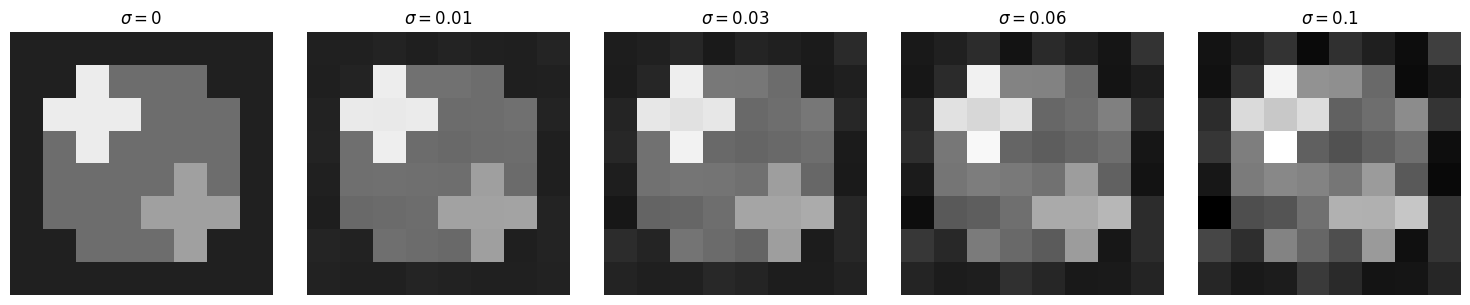

In [6]:
# Imágenes

# Calculamos una escala común para todas las reconstrucciones
vmin_imagenes = X_fantoma.min()
vmax_imagenes = X_fantoma.max()

for imagen in imagenes:
    vmin_imagenes = min(vmin_imagenes, imagen.min())
    vmax_imagenes = max(vmax_imagenes, imagen.max())

# Creamos la grilla de imágenes
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for i, s in enumerate(sigma):
    axes[i].imshow(imagenes[i].reshape(8, 8), cmap="gray", vmin=vmin_imagenes, vmax=vmax_imagenes)
    axes[i].set_title(f"$\\sigma={s}$")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## c) Análisis de los resultados con ruido

### 1. ¿Cómo cambia el error de reconstrucción al aumentar $\sigma$?
   A medida que el nivel de ruido $\sigma$ aumenta, el error relativo crece de forma prácticamente proporcional. Con $\sigma = 0$ el error es 0, pero al llegar a $\sigma = 0.10$ el error relativo sube a casi un 25%. Visualmente se puede ver cómo la imagen se degrada a causa del ruido.

### 2. ¿Por qué el residuo deja de ser nulo cuando agregamos ruido?
   Si no hay ruido, las mediciones $b_7$ vienen de una imagen real, por lo que existe una solución exacta que cumple las 119 ecuaciones a la vez ($A_7 x = b_7$) y el residuo es cero. 
   Al agregar ruido en cada medición, las mediciones se vuelven inconsistentes entre sí. Como tenemos más ecuaciones que incógnitas ($119 > 64$), ya no hay ninguna imagen de 64 píxeles capaz de satisfacer todas las mediciones ruidosas a la vez. El método de mínimos cuadrados busca la mejor aproximación posible, pero la distancia entre lo que predice el modelo ($A_7 \hat{x}_\sigma$) y las mediciones ($b_\sigma$) ya no puede ser cero.

### 3. ¿Por qué pueden aparecer valores negativos aunque los coeficientes de atenuación del fantoma sean no negativos?
   Los valores de los píxeles indican cuánto atenúa cada región al rayo. Por eso no deberían ser negativos: un valor negativo significaría que esa región aumenta la intensidad del rayo en lugar de debilitarlo, algo que no está contemplado en este modelo. En el fantoma utilizado, los valores se encuentran entre 0 y 0.8. Sin embargo, el método de mínimos cuadrados (`lstsq`) es un método matemático que permite que los píxeles tomen cualquier número real. Al intentar compensar las fluctuaciones aleatorias del ruido para que las sumas de los rayos den lo más cerca posible de $b_\sigma$, el algoritmo ajusta algunos píxeles hacia abajo, haciendo que en las zonas oscuras o de fondo aparezcan valores negativos (llegando a $-0.1326$ para $\sigma = 0.10$).